In [1]:
import numpy as np
import pandas as pd 
import seaborn as sns 
import  matplotlib.pyplot as plt

import scipy.stats as stats

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

from sklearn.preprocessing import PowerTransformer

In [3]:
concrete = pd.read_csv("concrete_data.csv")

In [4]:
concrete.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [5]:
concrete.shape

(1030, 9)

In [6]:
concrete.isnull().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [7]:
# Checking negative or 0's as Box Cox can't handle it

concrete.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [8]:
concrete.columns

Index(['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer',
       'Coarse Aggregate', 'Fine Aggregate', 'Age', 'Strength'],
      dtype='object')

In [9]:

x = concrete.drop(columns= ["Strength"])
y = concrete.iloc[:, -1]

In [10]:
X_train, X_test, Y_train, Y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

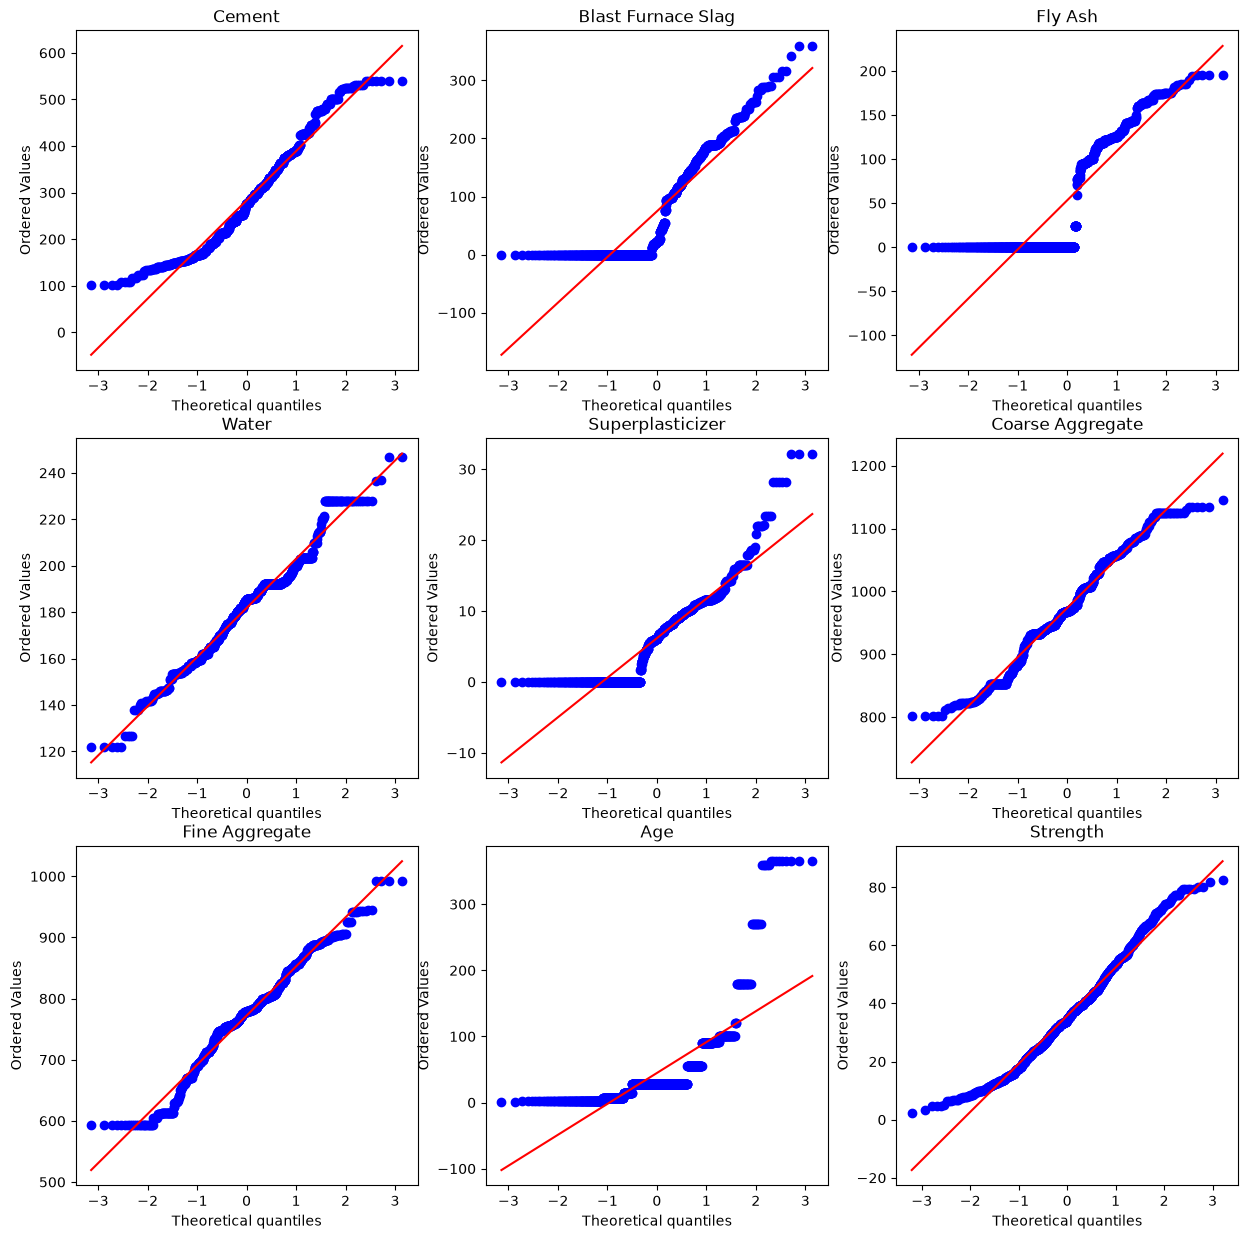

In [11]:
# plotting QQ plot for every feature before applying any transformation

plt.figure(figsize= (15, 15))

plt.subplot(3, 3, 1)
stats.probplot(X_train['Cement'], dist= "norm", plot= plt)
plt.title('Cement')

plt.subplot(3, 3, 2)
stats.probplot(X_train['Blast Furnace Slag'], dist= "norm", plot= plt)
plt.title('Blast Furnace Slag')

plt.subplot(3, 3, 3)
stats.probplot(X_train['Fly Ash'], dist= "norm", plot= plt)
plt.title('Fly Ash')

plt.subplot(3, 3, 4)
stats.probplot(X_train['Water'], dist= "norm", plot= plt)
plt.title('Water')

plt.subplot(3, 3, 5)
stats.probplot(X_train['Superplasticizer'], dist= "norm", plot= plt)
plt.title('Superplasticizer')

plt.subplot(3, 3, 6)
stats.probplot(X_train['Coarse Aggregate'], dist= "norm", plot= plt)
plt.title('Coarse Aggregate')

plt.subplot(3, 3, 7)
stats.probplot(X_train['Fine Aggregate'], dist= "norm", plot= plt)
plt.title('Fine Aggregate')

plt.subplot(3, 3, 8)
stats.probplot(X_train['Age'], dist= "norm", plot= plt)
plt.title('Age')

plt.subplot(3, 3, 9)
stats.probplot(concrete['Strength'], dist= "norm", plot= plt)
plt.title('Strength')

plt.show()


C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2814644519.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])


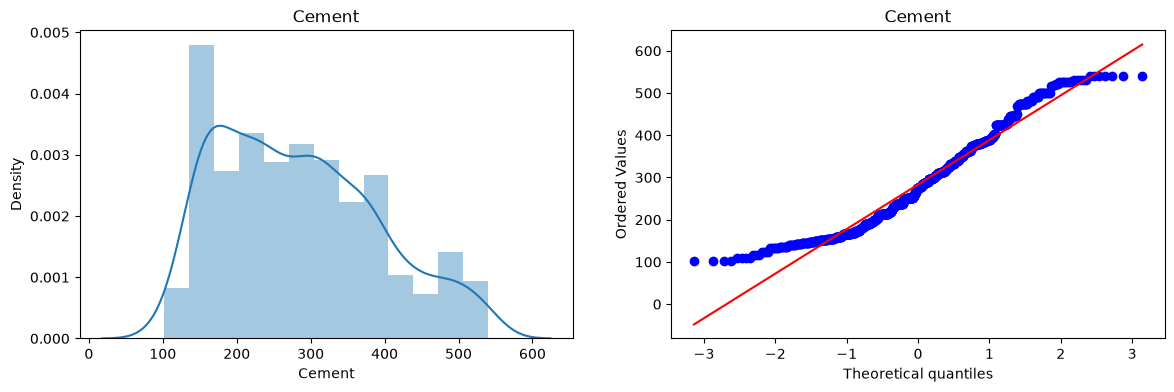

C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2814644519.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])


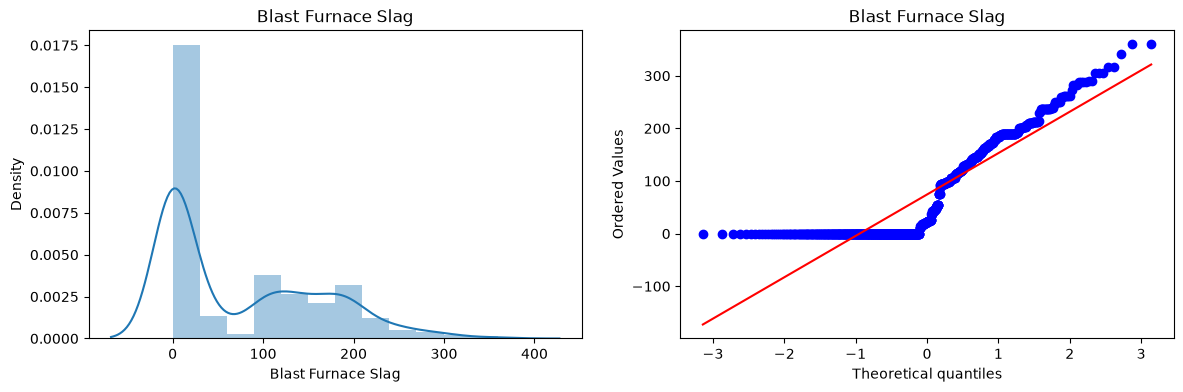

C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2814644519.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])


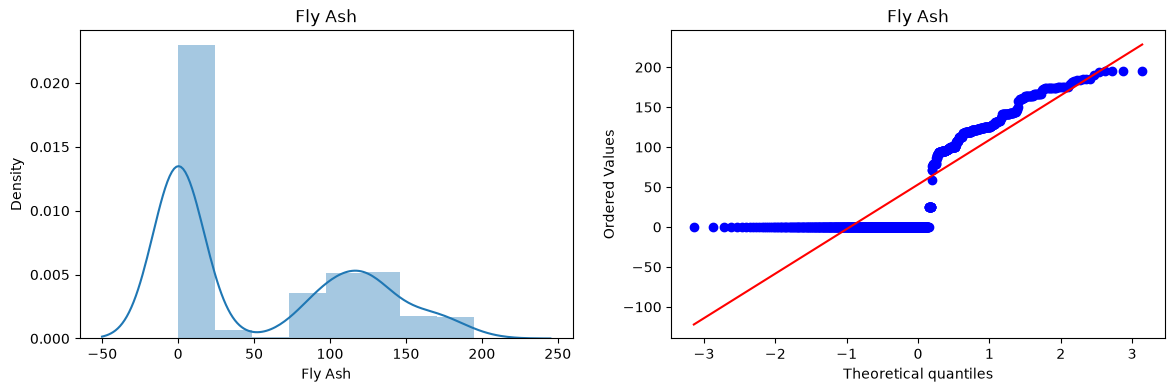

C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2814644519.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])


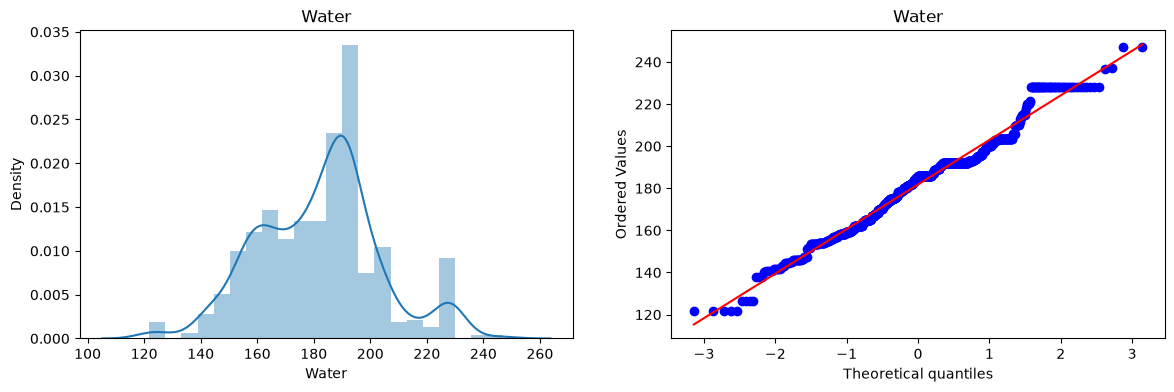

C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2814644519.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])


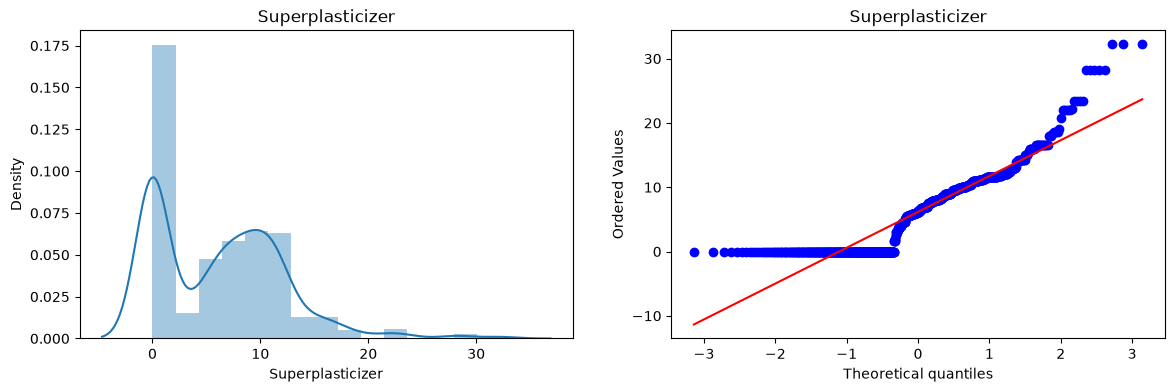

C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2814644519.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])


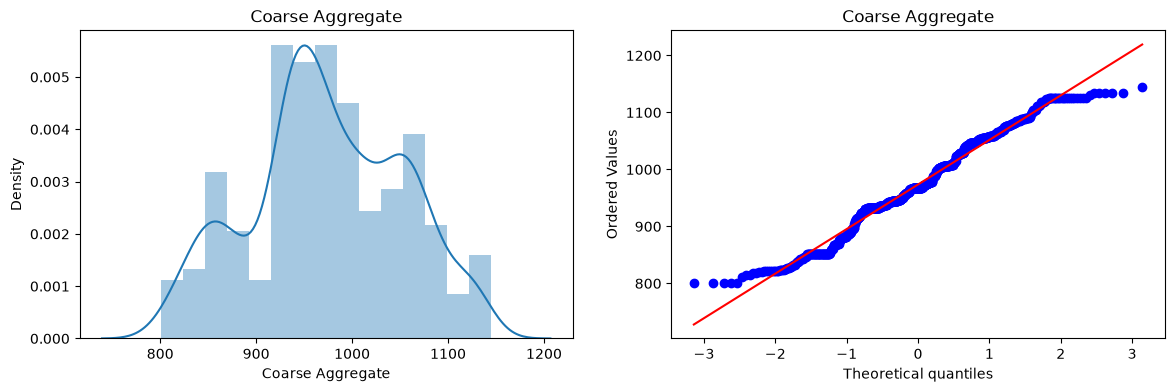

C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2814644519.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])


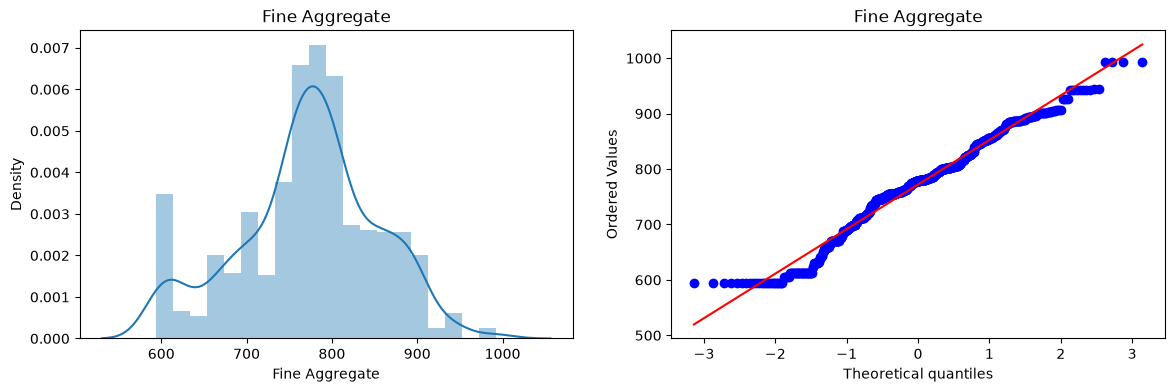

C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2814644519.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])


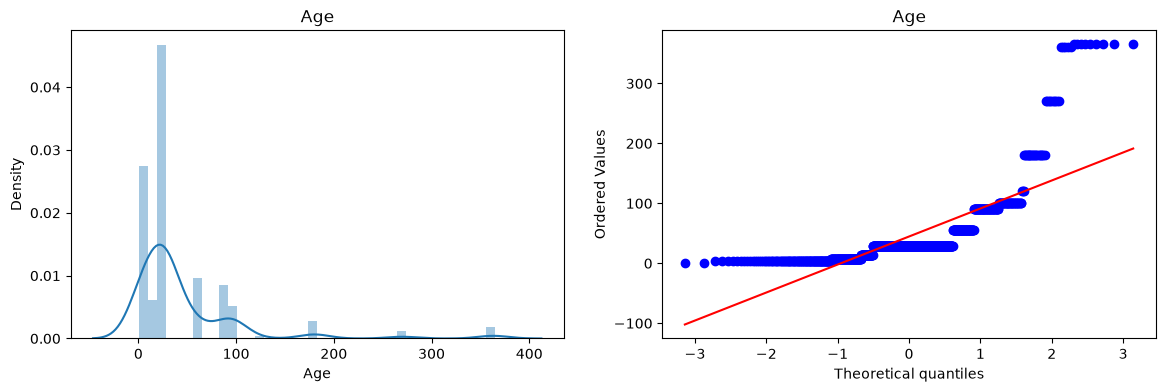

In [12]:
# Same above thing with loop and here distplot is also plotted 


for col in X_train.columns: 

    plt.figure(figsize=(14, 4))
    plt.subplot(121)
    sns.distplot(X_train[col])
    plt.title(col) 

    plt.subplot(122)
    stats.probplot(X_train[col], dist="norm", plot= plt) 
    plt.title(col)

    plt.show()

In [13]:
# Applying Linear Regression without any transformation

LR = LinearRegression()

LR.fit(X_train, Y_train)
y_pred_1 = LR.predict(X_test)  
r2_score(Y_test, y_pred_1)

0.627553179231485

## Applying Box Cox Transformation

In [14]:
BC = PowerTransformer(method= "box-cox")

# Here if any value is 0, then we are adding 0.000001 on it to make sure Box Cox can be applied
X_train_transformed = BC.fit_transform(X_train+0.000001)
X_test_transformed = BC.transform(X_test+0.000001)

# When for every column we calculate a lambda value 
# So now we want to know lambda value of each column 

pd.DataFrame({"Col_name": X_train.columns, "Lambda_val": BC.lambdas_})


,Col_name,Lambda_val
0,Cement,0.177025
1,Blast Furnace Slag,0.025093
2,Fly Ash,-0.038970
3,Water,0.772682
4,Superplasticizer,0.098811
5,Coarse Aggregate,1.129813
6,Fine Aggregate,1.782018
7,Age,0.066631


In [15]:
# Applying Linear Regression with transformation

LR = LinearRegression()

LR.fit(X_train_transformed, Y_train)
y_pred_2 = LR.predict(X_test_transformed)  
print("Accuracy After transformation: ", r2_score(Y_test, y_pred_2))
print("Accuracy Before transformation: ", r2_score(Y_test, y_pred_1))

Accuracy After transformation:  0.8047825008078886
Accuracy Before transformation:  0.627553179231485


In [16]:
# But above we calculated only one time, So we will use Cross val Score 
BC_1 = PowerTransformer(method= "box-cox")
X_transformed = BC_1.fit_transform(x + 0.000001)

LR_1 = LinearRegression()

score = cross_val_score(
    LR_1,  
    X_transformed, 
    y, 
    cv= 10, 
    scoring="r2"
)

print("Scores of each fold: ", score) 
print("Average Score: ", score.mean())

Scores of each fold:  [0.34951068 0.7408767  0.66626161 0.61846034 0.66676101 0.71924967
 0.7303795  0.82083528 0.59328805 0.56114189]
Average Score:  0.6466764736678003


C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2499621782.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])
C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2499621782.py:12: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train_transformed_DF[col])


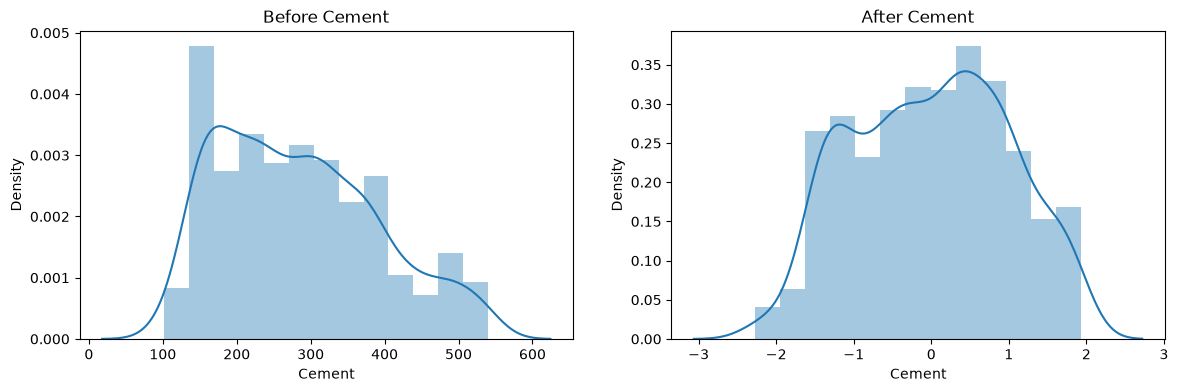

C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2499621782.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])
C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2499621782.py:12: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train_transformed_DF[col])


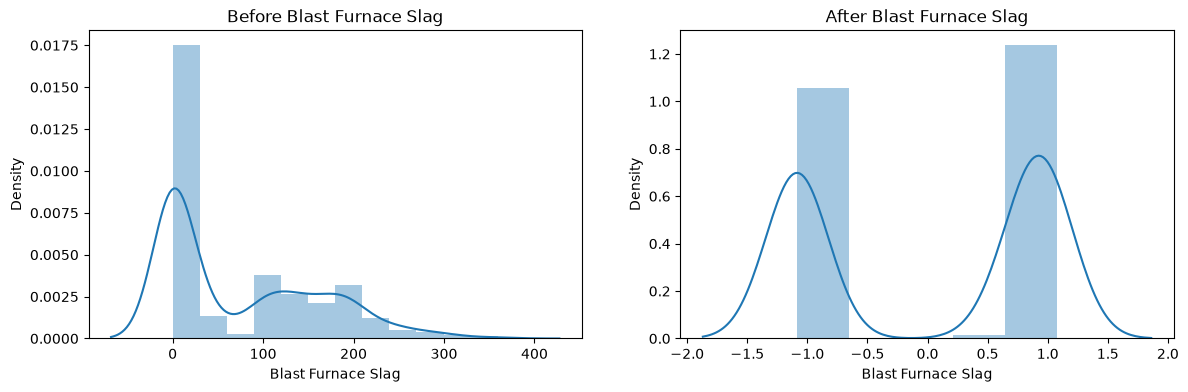

C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2499621782.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])
C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2499621782.py:12: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train_transformed_DF[col])


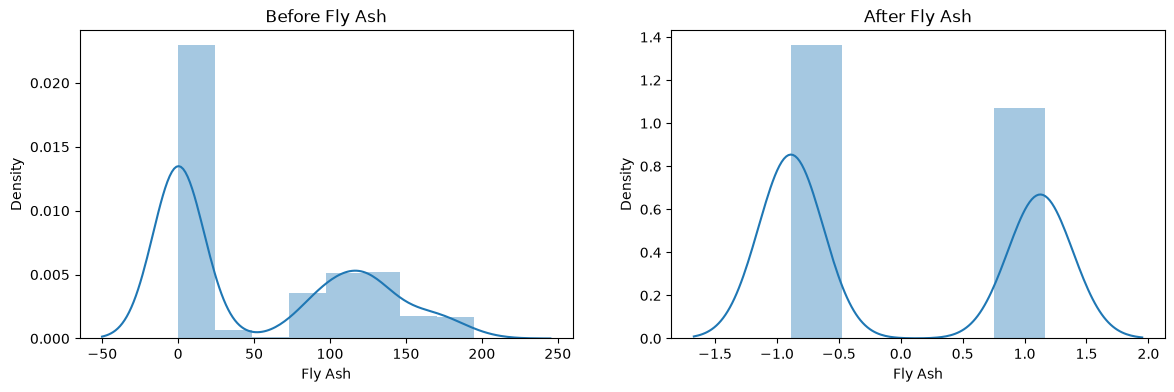

C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2499621782.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])
C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2499621782.py:12: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train_transformed_DF[col])


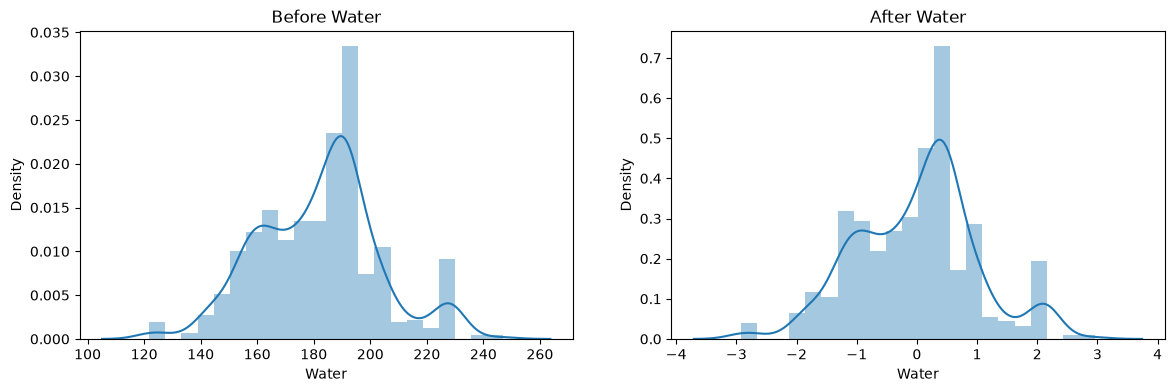

C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2499621782.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])
C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2499621782.py:12: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train_transformed_DF[col])


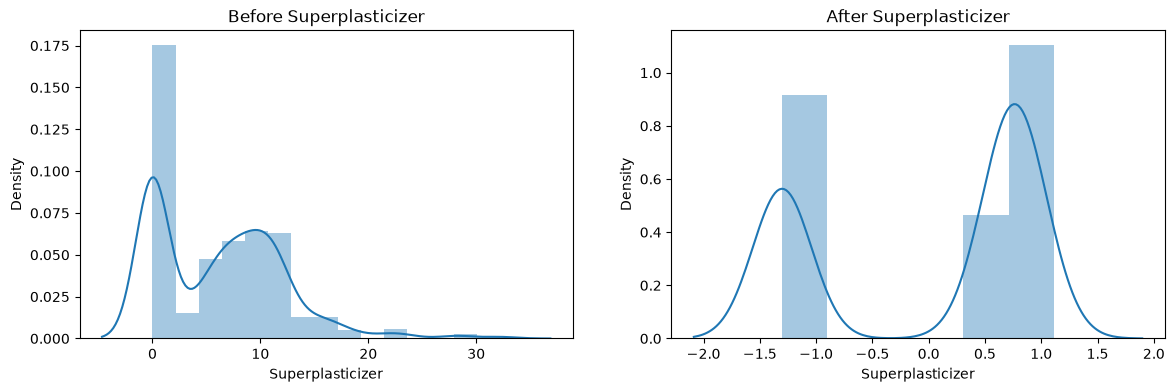

C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2499621782.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])
C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2499621782.py:12: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train_transformed_DF[col])


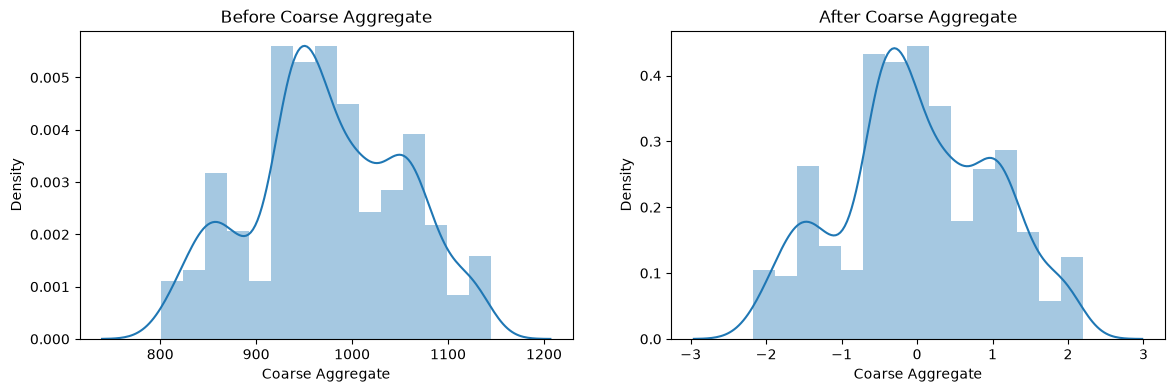

C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2499621782.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])
C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2499621782.py:12: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train_transformed_DF[col])


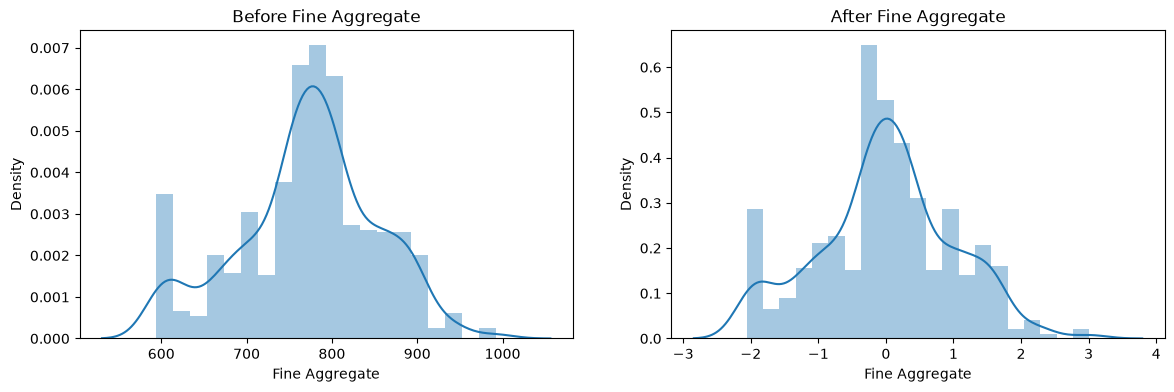

C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2499621782.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])
C:\Users\Asus\AppData\Local\Temp\ipykernel_8864\2499621782.py:12: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train_transformed_DF[col])


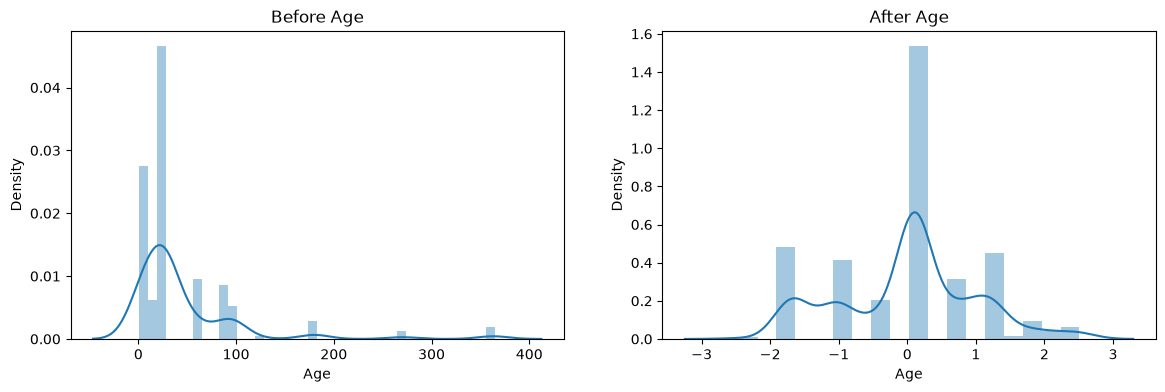

In [17]:
# Now plotting before and After transformation 
X_train_transformed_DF = pd.DataFrame(X_train_transformed, columns= X_train.columns)

for col in X_train_transformed_DF.columns: 
    plt.figure(figsize=(14, 4))

    plt.subplot(1, 2, 1) 
    sns.distplot(X_train[col]) 
    plt.title("Before " + col)  

    plt.subplot(1, 2, 2)
    sns.distplot(X_train_transformed_DF[col]) 
    plt.title("After " + col) 

    plt.show()

## Applying Yoe Johnsson tRANSFORMATION

In [31]:

# By default PowerTransformer is set tp Yoe-Johnsson
YJ = PowerTransformer()

X_train_transformed_2 = YJ.fit_transform(X_train)
X_test_transformed_2 = YJ.transform(X_test) 

LR_2 = LinearRegression() 

LR_2.fit(X_train_transformed_2, Y_train)
y_pred_3 = LR_2.predict(X_test_transformed_2)

print("r2 Score: ", r2_score(Y_test, y_pred_3))

print(pd.DataFrame({"Col's: ": X_train.columns, "YJ Lambdas: ": YJ.lambdas_}))

r2 Score:  0.8161906511066099
              Col's:   YJ Lambdas: 
0              Cement      0.174348
1  Blast Furnace Slag      0.015715
2             Fly Ash     -0.161447
3               Water      0.771307
4    Superplasticizer      0.253935
5    Coarse Aggregate      1.130050
6      Fine Aggregate      1.783100
7                 Age      0.019885


In [29]:
# Box Cox had r2 score 80 and Yoe Jihnsson has 81, that means there's positive feedback 

# Applying Cross val Score 

YJ_2 = PowerTransformer()

X_transformed_2 = YJ_2.fit_transform(x) 
LR_3 = LinearRegression() 

np.mean(cross_val_score(LR_3, X_transformed_2, y, scoring= "r2"))

np.float64(0.6834625126992433)

In [20]:
pd.DataFrame({"Col's names": X_train.columns, "BC Lambdas": BC_1.lambdas_, "YJ Lambdas": YJ_2.lambdas_ })

,Col's names,BC Lambdas,YJ Lambdas
0,Cement,0.172271,0.169544
1,Blast Furnace Slag,0.025273,0.016633
2,Fly Ash,-0.032412,-0.136480
3,Water,0.809568,0.808438
4,Superplasticizer,0.099711,0.264160
5,Coarse Aggregate,1.129168,1.129395
6,Fine Aggregate,1.829625,1.830764
7,Age,0.048975,0.001771


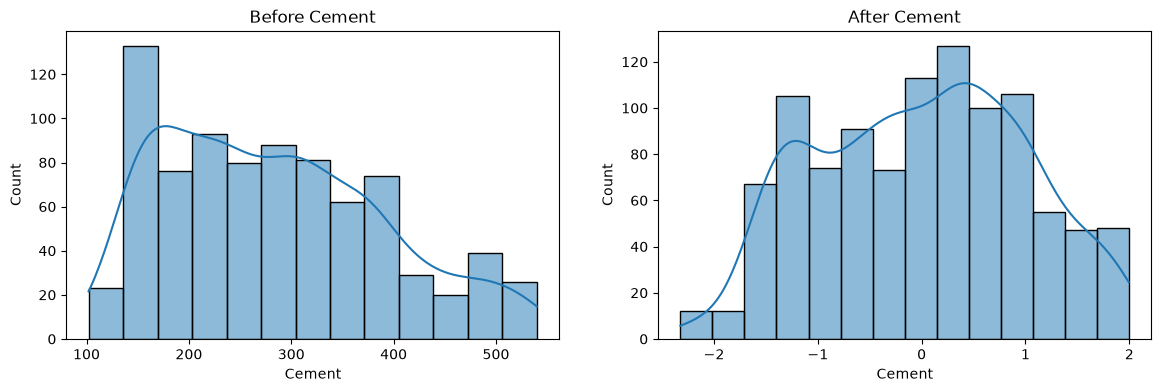

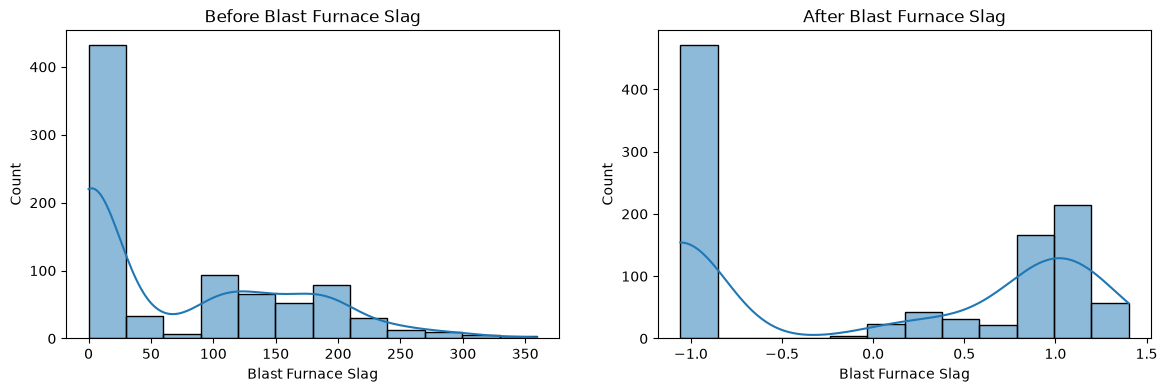

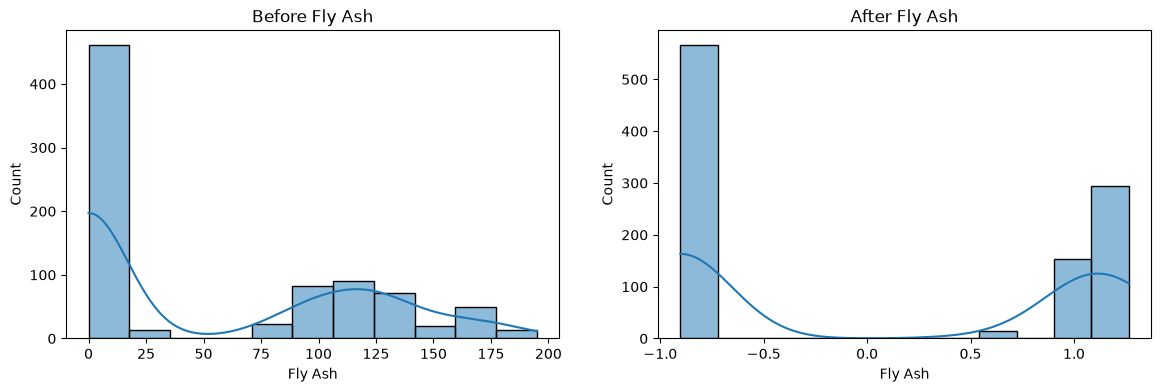

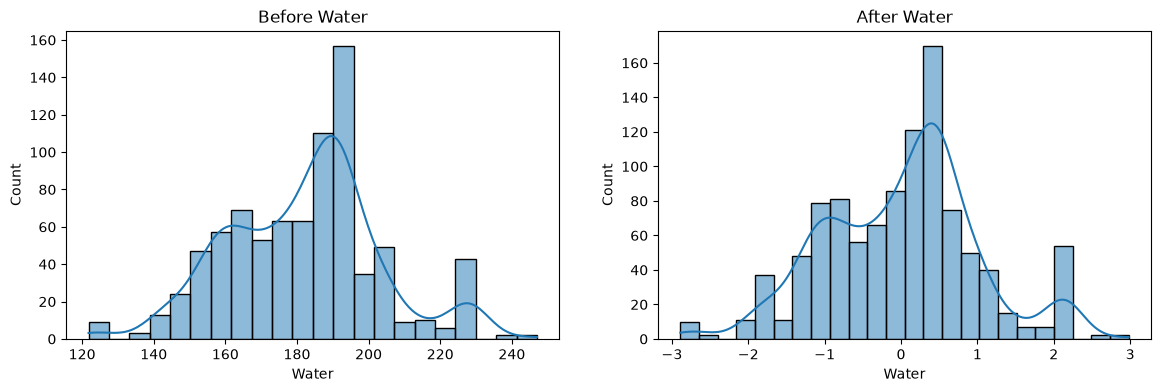

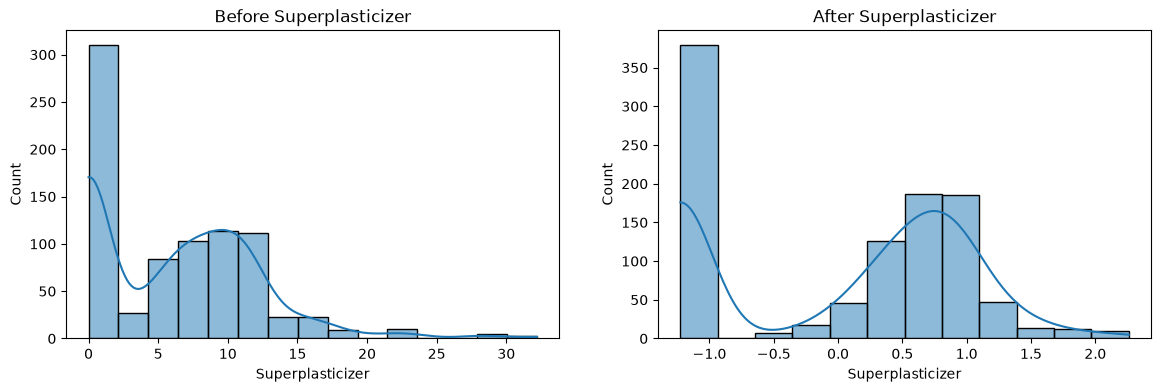

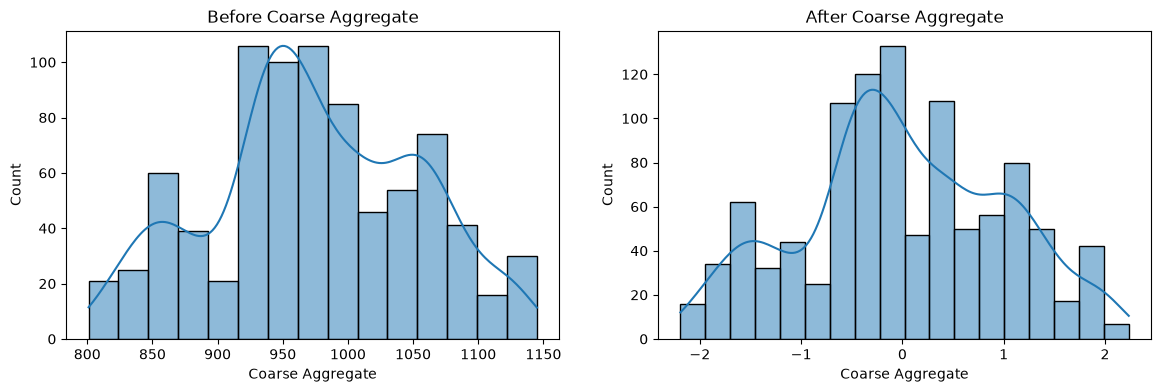

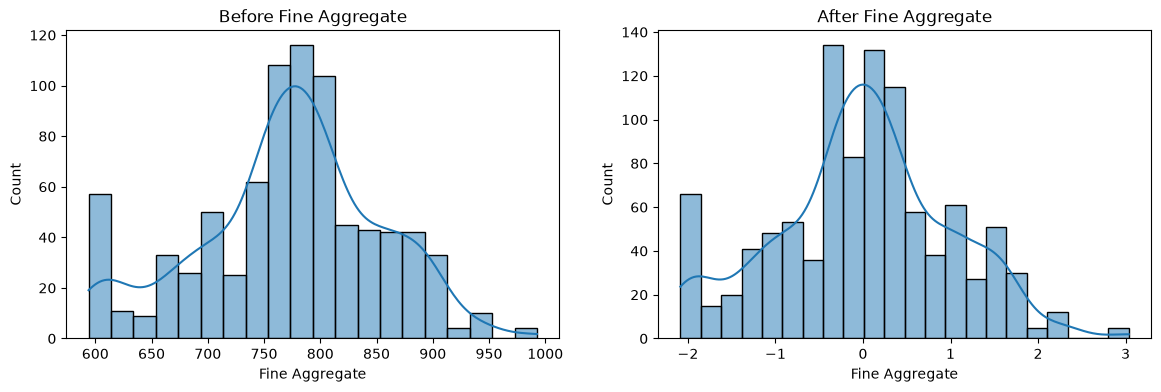

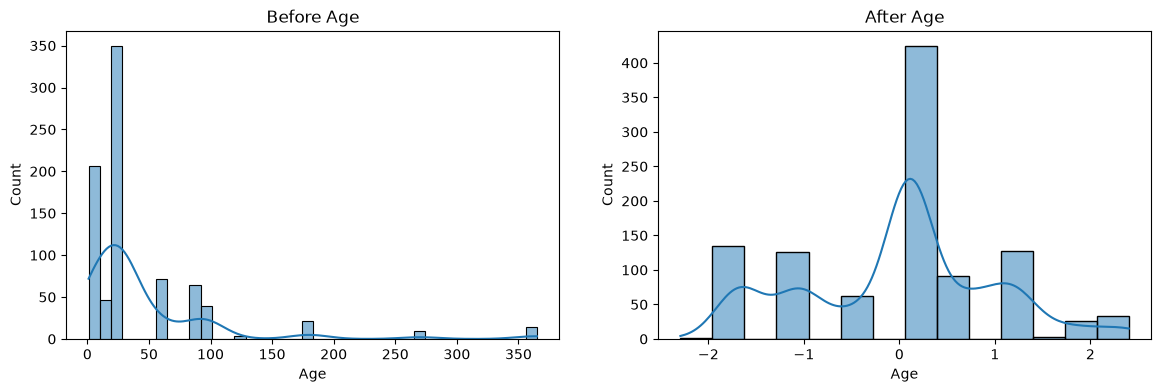

In [28]:
YJ_X_DF = pd.DataFrame(X_transformed_2, columns= X_train.columns)

for col2 in YJ_X_DF.columns: 

    plt.figure(figsize= (14, 4))

    plt.subplot(1, 2, 1) 
    sns.histplot(X_train[col2], kde= True) 
    plt.title("Before "+ col2)

    
    plt.subplot(1, 2, 2) 
    sns.histplot(YJ_X_DF[col2], kde= True) 
    plt.title("After "+ col2)

    plt.show()